# 📊 02. Exploratory Data Analysis (EDA)
**Project**: E-Commerce Discount Impact Analysis & Profit Prediction  
**Role**: Senior Data Scientist & Data Analyst

---

## Overview & Objectives
In this notebook, we perform an in-depth exploratory data analysis to evaluate:
1. **Descriptive Statistics**: Compare Mean, Median, Std Dev, Quartiles, and IQR for Discounted vs. Non-Discounted orders.
2. **Distribution & Skewness**: Model order value probability density distributions using KDE and histograms.
3. **Outlier Diagnostics**: Inspect boxplots for order value and realized gross profit margin.
4. **Basket Size Decomposition**: Unpack why discounted orders generate higher AOV (multi-item cart accumulation).
5. **Margin Compression Curve**: Quantify profit margin erosion and identify loss-making thresholds across discount tiers.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'figure.titlesize': 14,
    'figure.titleweight': 'bold'
})

os.makedirs('reports/figures', exist_ok=True)

orders_df = pd.read_csv('data/processed/orders_delivered_aggregated.csv')
items_df = pd.read_csv('data/processed/order_items_delivered.csv')
print(f"Loaded {len(orders_df):,} delivered orders and {len(items_df):,} line items.")

Loaded 4,386 delivered orders and 10,970 line items.


## Step 1: Descriptive Summary Statistics

In [2]:
def compute_group_statistics(delivered_orders: pd.DataFrame, col: str = 'order_value') -> pd.DataFrame:
    # Computes full parametric and non-parametric summary metrics for both groups
    groups = {
        'Discounted Orders': delivered_orders[delivered_orders['has_discount']][col],
        'Non-Discounted Orders': delivered_orders[~delivered_orders['has_discount']][col]
    }
    rows = []
    for label, s in groups.items():
        q25, q75 = s.quantile(0.25), s.quantile(0.75)
        rows.append({
            'Group': label,
            'Count (n)': len(s),
            'Mean': f"${s.mean():,.2f}",
            'Std Dev': f"${s.std():,.2f}",
            'Median': f"${s.median():,.2f}",
            'IQR': f"${q75 - q25:,.2f}",
            '25th Pct': f"${q25:,.2f}",
            '75th Pct': f"${q75:,.2f}",
            'Min': f"${s.min():,.2f}",
            'Max': f"${s.max():,.2f}",
            'Skewness': f"{s.skew():.3f}"
        })
    return pd.DataFrame(rows).set_index('Group')

print("=== ORDER VALUE (AOV) DESCRIPTIVE STATISTICS ===")
display(compute_group_statistics(orders_df, 'order_value'))

print("\n=== PROFIT MARGIN % DESCRIPTIVE STATISTICS ===")
display(compute_group_statistics(orders_df, 'profit_margin_pct'))

=== ORDER VALUE (AOV) DESCRIPTIVE STATISTICS ===


,Count (n),Mean,Std Dev,Median,IQR,25th Pct,75th Pct,Min,Max,Skewness
Group,,,,,,,,,,
Discounted Orders,4230,"$35,550.65","$22,755.74","$32,649.20","$32,678.93","$17,403.00","$50,081.93",$255.20,"$136,660.20",0.708
Non-Discounted Orders,156,"$18,799.19","$14,431.33","$14,292.00","$20,799.00","$7,245.00","$28,044.00",$375.00,"$72,370.00",1.098



=== PROFIT MARGIN % DESCRIPTIVE STATISTICS ===


,Count (n),Mean,Std Dev,Median,IQR,25th Pct,75th Pct,Min,Max,Skewness
Group,,,,,,,,,,
Discounted Orders,4230,$32.24,$10.09,$33.26,$13.47,$25.99,$39.47,$-10.94,$53.29,-0.543
Non-Discounted Orders,156,$38.65,$10.18,$38.62,$17.27,$30.31,$47.58,$16.79,$54.34,-0.123


## Step 2: Distribution of Order Values (AOV)

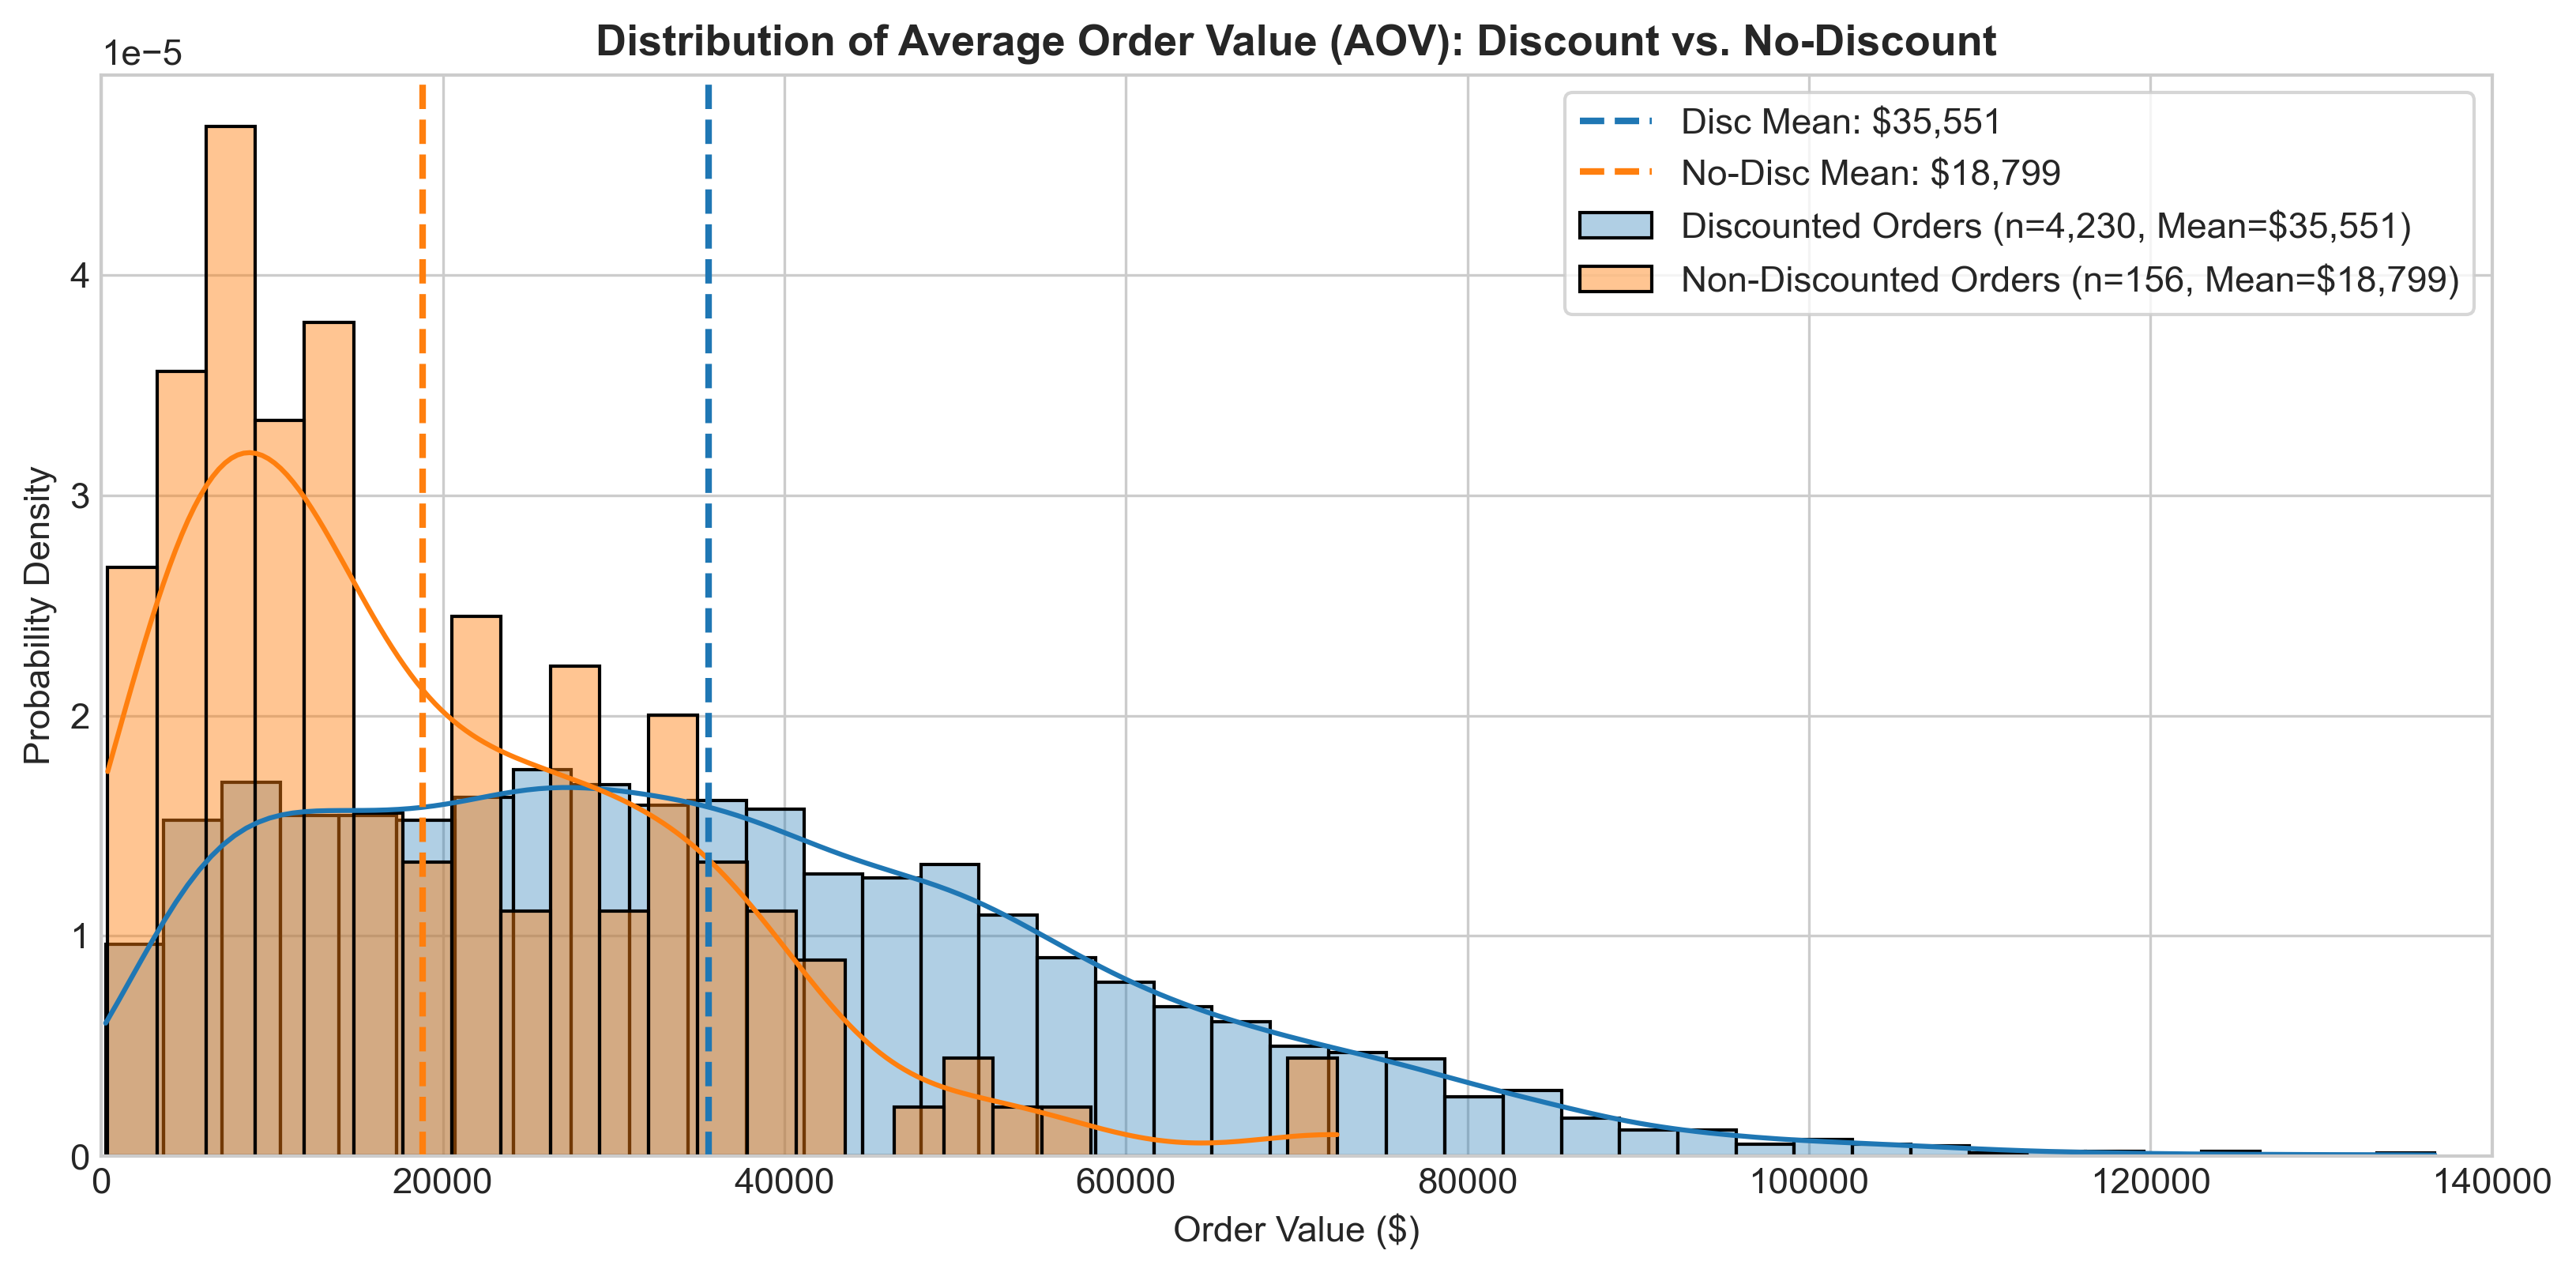

In [3]:
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)

disc_vals = orders_df[orders_df['has_discount']]['order_value']
nodisc_vals = orders_df[~orders_df['has_discount']]['order_value']

sns.histplot(disc_vals, kde=True, stat="density", bins=40, color="#1f77b4", alpha=0.35, 
             label=f"Discounted Orders (n={len(disc_vals):,}, Mean=${disc_vals.mean():,.0f})", ax=ax)
sns.histplot(nodisc_vals, kde=True, stat="density", bins=25, color="#ff7f0e", alpha=0.45, 
             label=f"Non-Discounted Orders (n={len(nodisc_vals):,}, Mean=${nodisc_vals.mean():,.0f})", ax=ax)

ax.axvline(disc_vals.mean(), color="#1f77b4", linestyle="--", linewidth=2, label=f"Disc Mean: ${disc_vals.mean():,.0f}")
ax.axvline(nodisc_vals.mean(), color="#ff7f0e", linestyle="--", linewidth=2, label=f"No-Disc Mean: ${nodisc_vals.mean():,.0f}")

ax.set_title("Distribution of Average Order Value (AOV): Discount vs. No-Discount")
ax.set_xlabel("Order Value ($)")
ax.set_ylabel("Probability Density")
ax.legend(frameon=True, facecolor="white", loc="upper right")
ax.set_xlim(0, 140000)

plt.tight_layout()
plt.savefig('reports/figures/01_aov_distribution.png', bbox_inches='tight')
plt.show()

## Step 3: Order Value and Profit Margin Boxplots

C:\Users\Pratik Giri\AppData\Local\Temp\ipykernel_9320\1435155332.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=orders_plot, x='Segment', y='order_value', palette=palette, ax=ax1, width=0.45,
C:\Users\Pratik Giri\AppData\Local\Temp\ipykernel_9320\1435155332.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=orders_plot, x='Segment', y='profit_margin_pct', palette=palette, ax=ax2, width=0.45,


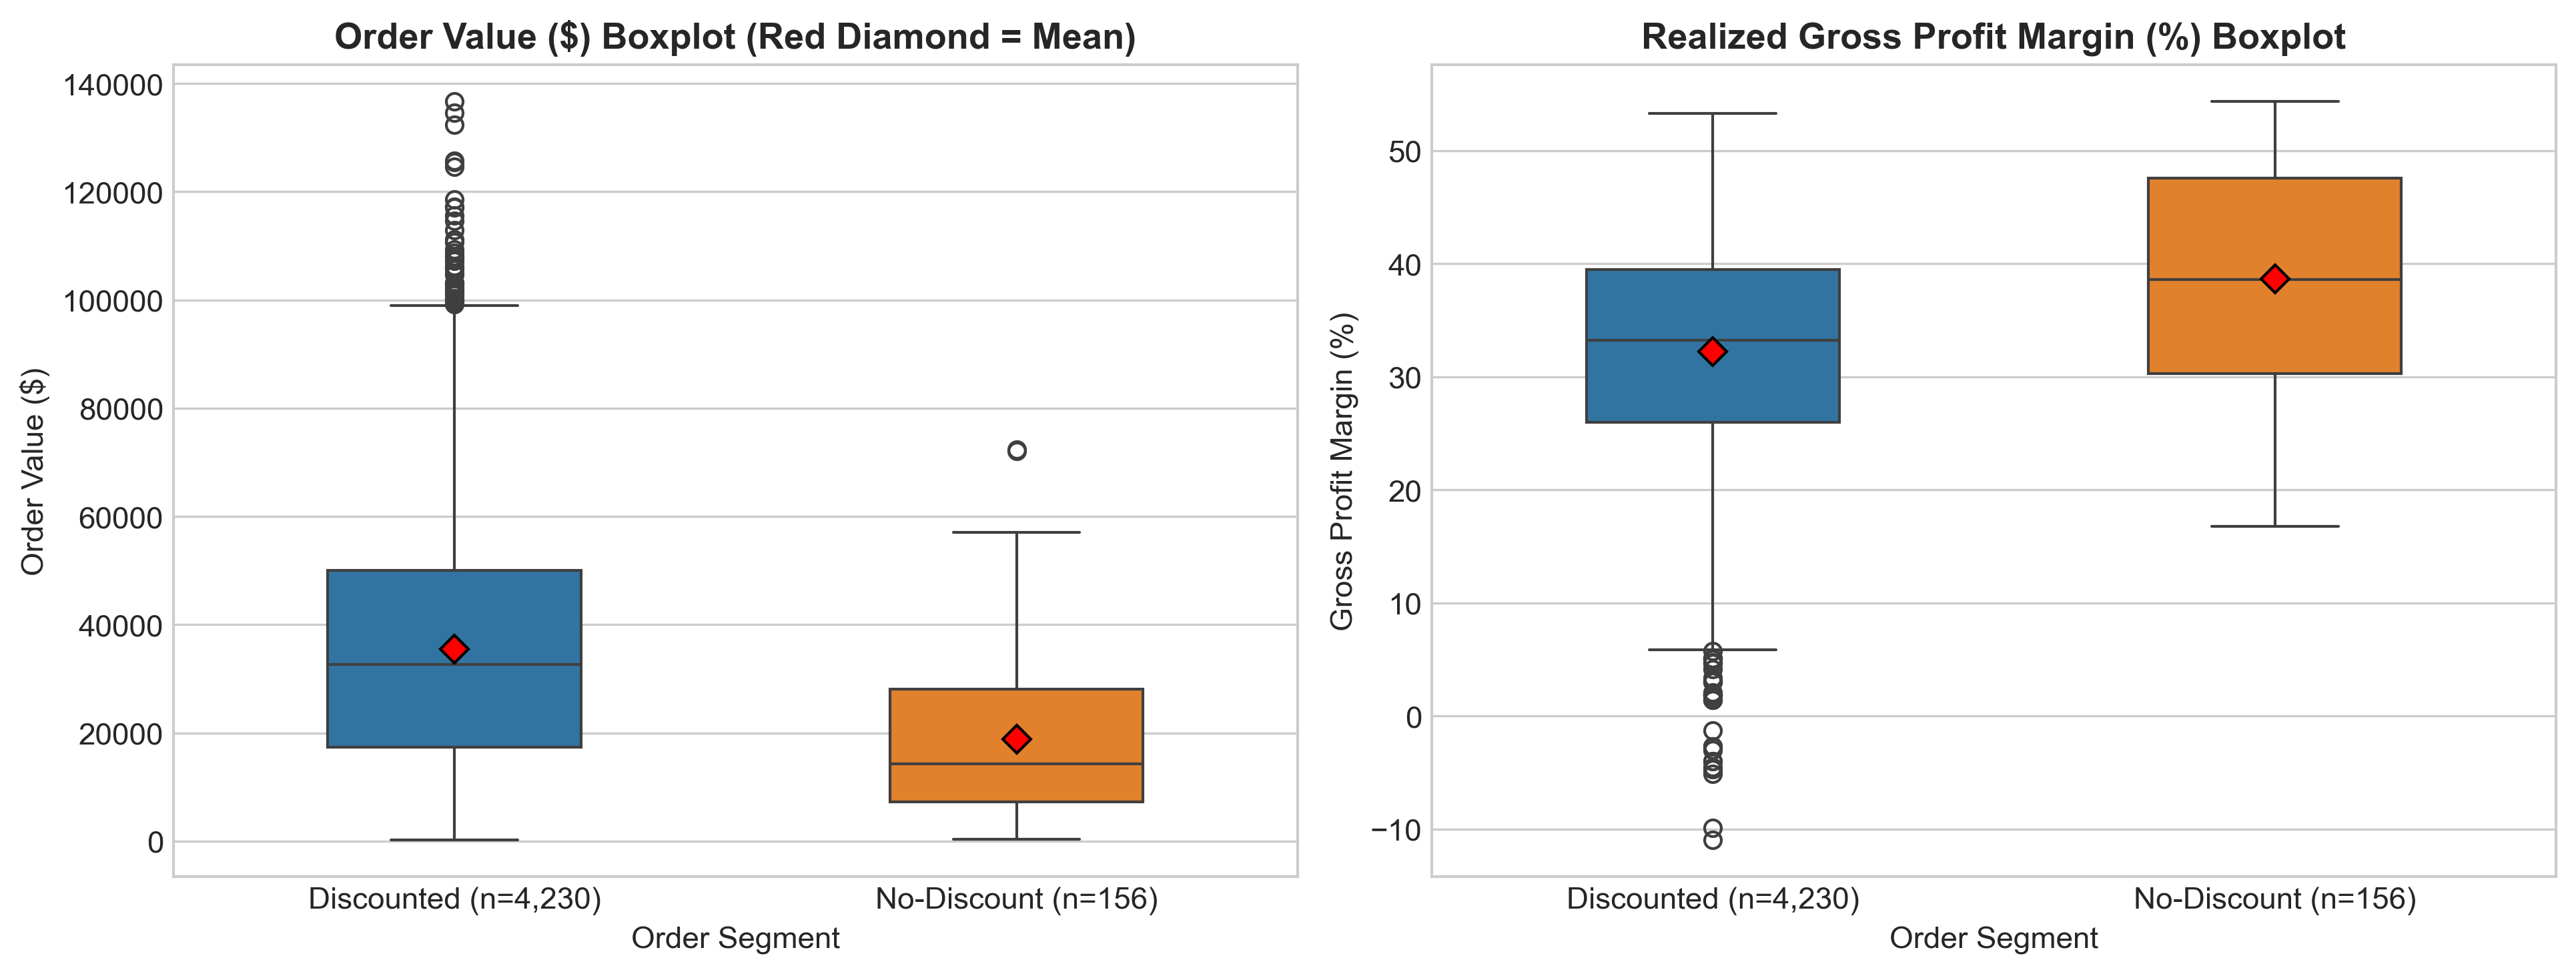

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

orders_plot = orders_df.copy()
orders_plot['Segment'] = np.where(orders_plot['has_discount'], 'Discounted (n=4,230)', 'No-Discount (n=156)')
palette = {'Discounted (n=4,230)': '#1f77b4', 'No-Discount (n=156)': '#ff7f0e'}

sns.boxplot(data=orders_plot, x='Segment', y='order_value', palette=palette, ax=ax1, width=0.45,
            showmeans=True, meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": 7})
ax1.set_title("Order Value ($) Boxplot (Red Diamond = Mean)")
ax1.set_ylabel("Order Value ($)")
ax1.set_xlabel("Order Segment")

sns.boxplot(data=orders_plot, x='Segment', y='profit_margin_pct', palette=palette, ax=ax2, width=0.45,
            showmeans=True, meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": 7})
ax2.set_title("Realized Gross Profit Margin (%) Boxplot")
ax2.set_ylabel("Gross Profit Margin (%)")
ax2.set_xlabel("Order Segment")

plt.tight_layout()
plt.savefig('reports/figures/02_aov_boxplots.png', bbox_inches='tight')
plt.show()

## Step 4: Cart Composition & Basket Size Decomposition

C:\Users\Pratik Giri\AppData\Local\Temp\ipykernel_9320\3947421700.py:17: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=orders_plot, x='Segment', y='total_quantity', palette=palette, ax=ax2, ci=None, width=0.4, edgecolor='black')
C:\Users\Pratik Giri\AppData\Local\Temp\ipykernel_9320\3947421700.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=orders_plot, x='Segment', y='total_quantity', palette=palette, ax=ax2, ci=None, width=0.4, edgecolor='black')


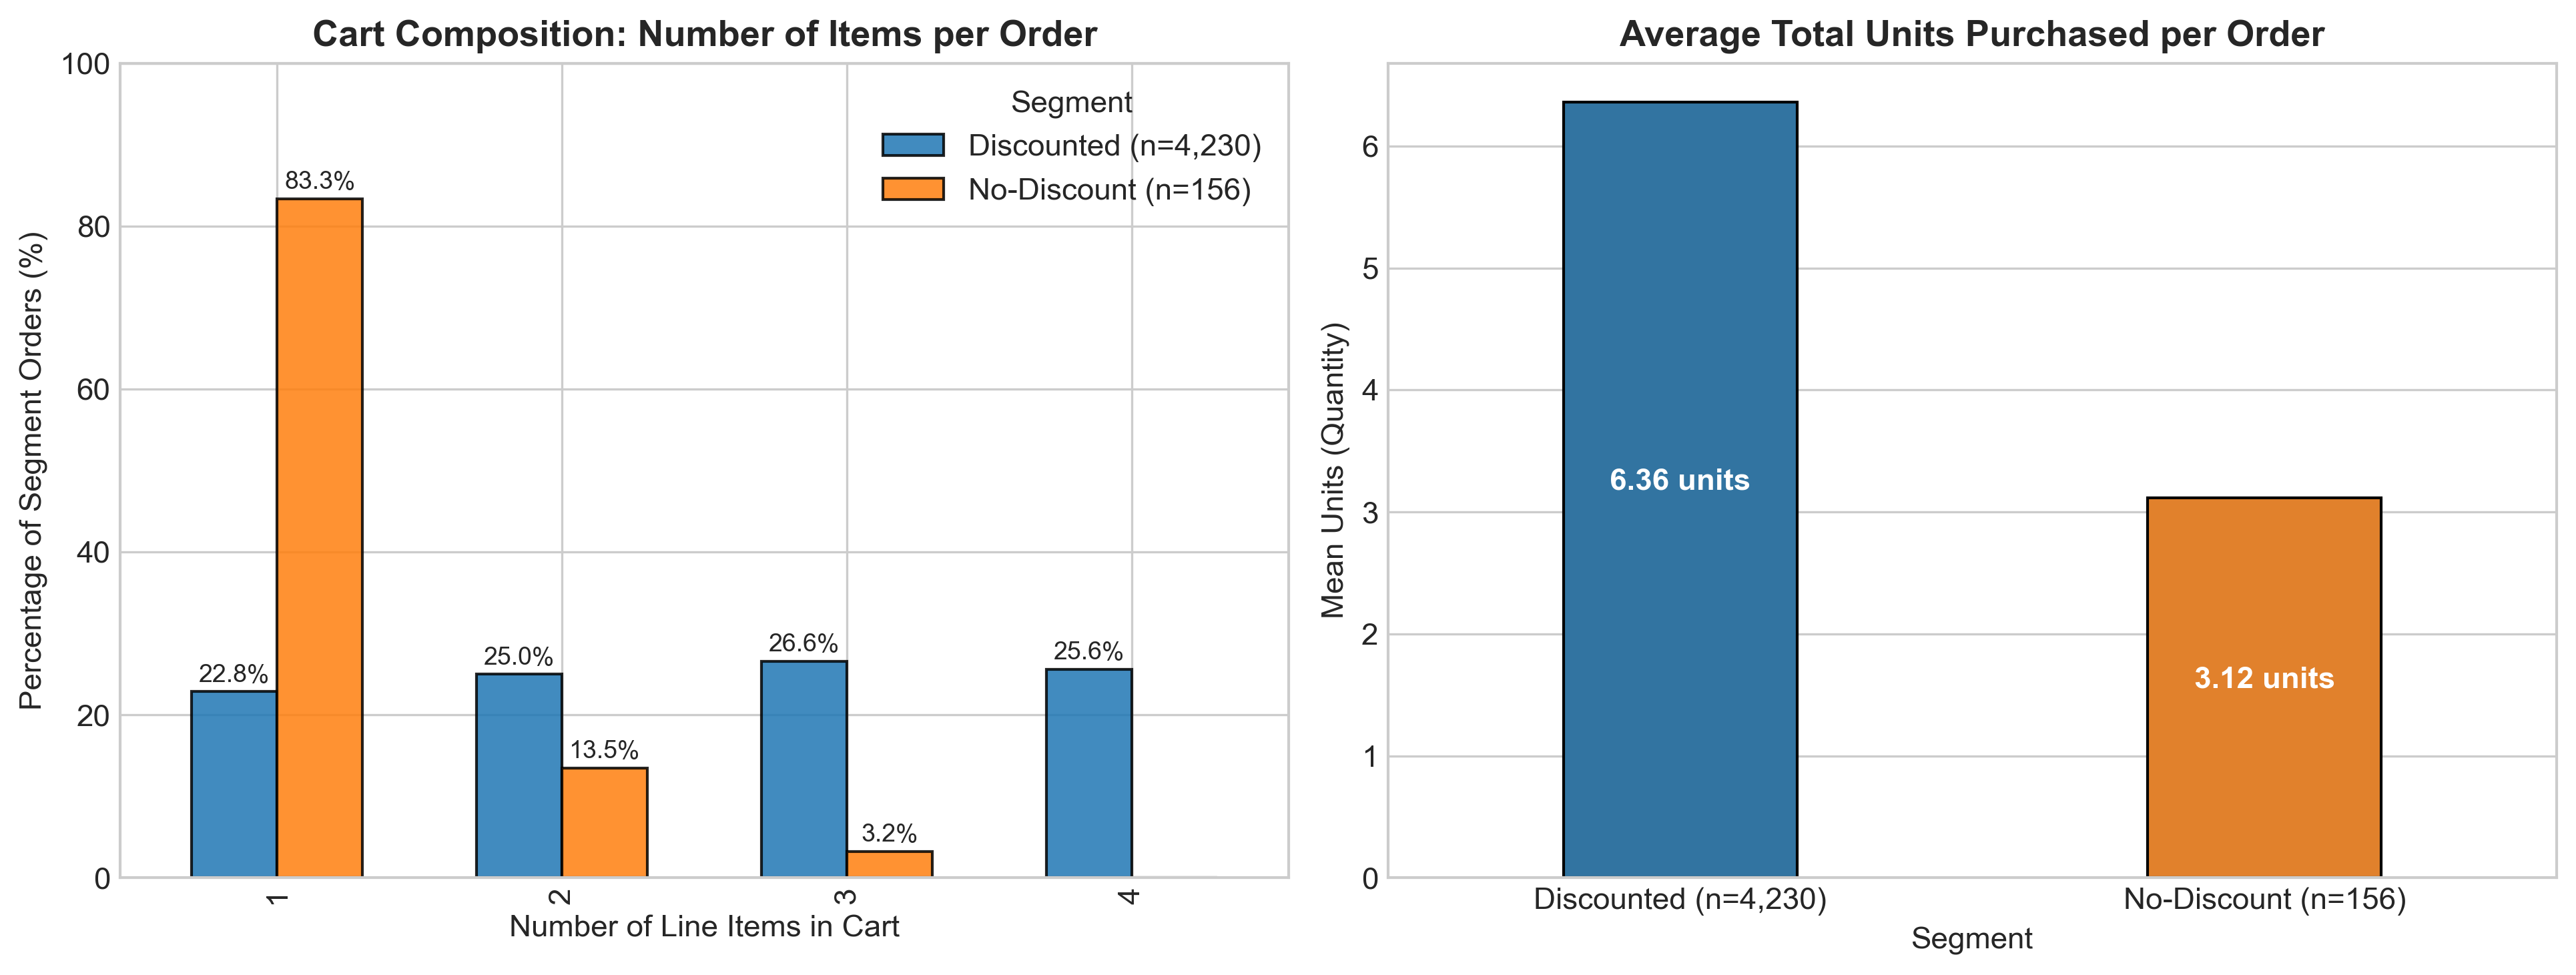

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

basket_counts = orders_plot.groupby(['item_count', 'Segment']).size().unstack(fill_value=0)
basket_pct = basket_counts.div(basket_counts.sum(axis=0), axis=1) * 100

basket_pct.plot(kind='bar', ax=ax1, color=['#1f77b4', '#ff7f0e'], width=0.6, edgecolor='black', alpha=0.85)
ax1.set_title("Cart Composition: Number of Items per Order")
ax1.set_xlabel("Number of Line Items in Cart")
ax1.set_ylabel("Percentage of Segment Orders (%)")
ax1.set_ylim(0, 100)
for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1.2), ha='center', fontsize=9)

# Total units purchased
sns.barplot(data=orders_plot, x='Segment', y='total_quantity', palette=palette, ax=ax2, ci=None, width=0.4, edgecolor='black')
ax2.set_title("Average Total Units Purchased per Order")
ax2.set_ylabel("Mean Units (Quantity)")
for p in ax2.patches:
    h = p.get_height()
    ax2.annotate(f"{h:.2f} units", (p.get_x() + p.get_width() / 2., h / 2), ha='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('reports/figures/03_basket_size_comparison.png', bbox_inches='tight')
plt.show()

## Step 5: Profit Margin Compression Across Discount Tiers

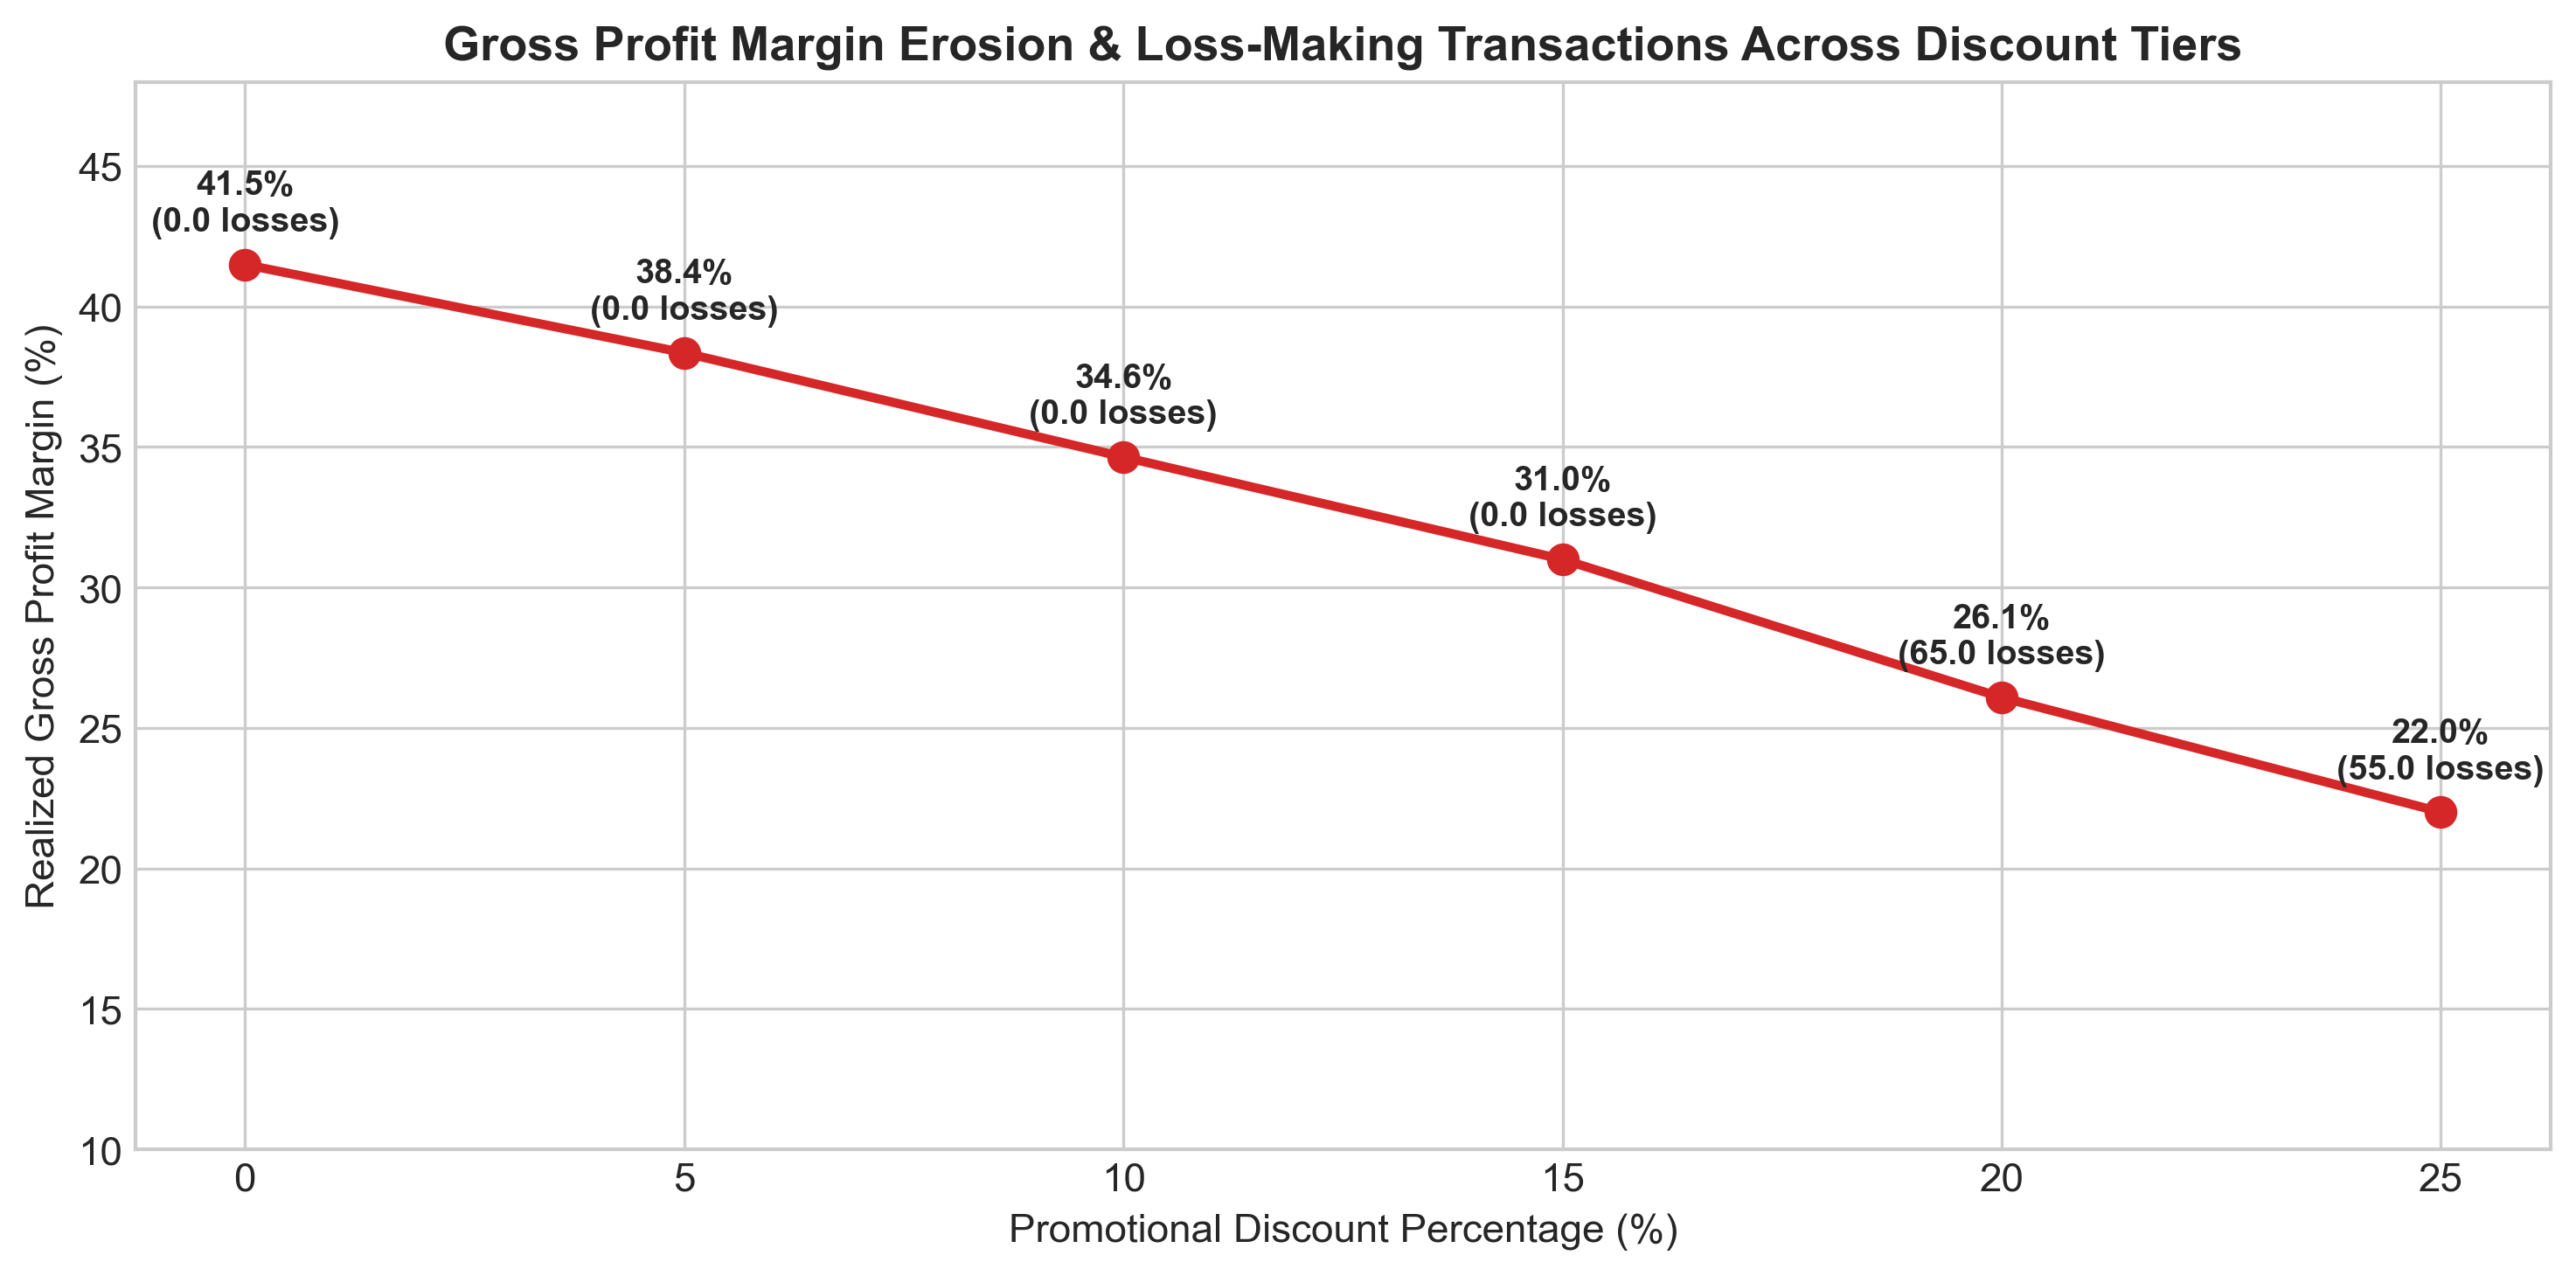

Discount Tier Breakdown:


,DiscountPct,total_sales,total_profit,loss_making_items,item_count,margin_pct,loss_rate_pct
0,0,25627261.00,10633777.00,0,1625,41.494005,0.000000
1,5,33314448.00,12777306.00,0,2225,38.353648,0.000000
2,10,38081115.00,13193378.00,0,2722,34.645461,0.000000
3,15,30460267.65,9443305.65,0,2261,31.002044,0.000000
4,20,19299382.40,5035020.40,65,1578,26.089023,4.119138
5,25,6529465.50,1437150.50,55,559,22.010232,9.838998


In [6]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

tier_stats = items_df.groupby('DiscountPct').agg(
    total_sales=('SalesAmount', 'sum'),
    total_profit=('Profit', 'sum'),
    loss_making_items=('Profit', lambda p: (p < 0).sum()),
    item_count=('OrderDetailID', 'count')
).reset_index()

tier_stats['margin_pct'] = (tier_stats['total_profit'] / tier_stats['total_sales']) * 100
tier_stats['loss_rate_pct'] = (tier_stats['loss_making_items'] / tier_stats['item_count']) * 100

ax.plot(tier_stats['DiscountPct'], tier_stats['margin_pct'], marker='o', linewidth=2.5, color='#d62728', markersize=8, label='Gross Margin %')
for _, row in tier_stats.iterrows():
    ax.annotate(f"{row['margin_pct']:.1f}%\n({row['loss_making_items']} losses)", 
                (row['DiscountPct'], row['margin_pct'] + 1.2), ha='center', fontweight='bold', fontsize=9.5)

ax.set_title("Gross Profit Margin Erosion & Loss-Making Transactions Across Discount Tiers")
ax.set_xlabel("Promotional Discount Percentage (%)")
ax.set_ylabel("Realized Gross Profit Margin (%)")
ax.set_ylim(10, 48)
ax.axhline(0, color='gray', linestyle=':')

plt.tight_layout()
plt.savefig('reports/figures/04_margin_compression_tier.png', bbox_inches='tight')
plt.show()

print("Discount Tier Breakdown:")
display(tier_stats)